# 05 · Face filters

The predicted keypoints are enough to place an overlay on a face. This notebook puts sunglasses on every face that the pipeline from notebook 04 detects. All positions come from **v2's predictions**, not from ground-truth annotations.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # make project modules importable

import config

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import metrics
from data_load import read_rgb, split_by_identity
from models import load_trained
from pipeline import DEFAULT_PAD, crop_face, detect_faces, load_rgb, overlay_sunglasses, predict_keypoints

net = load_trained(config.FINAL_WEIGHTS)
print("model:", config.FINAL_WEIGHTS.name, "| device:", config.DEVICE)

model: keypoints_cnn_v2.pt | device: mps


## The overlay image

`sunglasses.png` has a fourth **alpha** channel that marks how opaque each pixel is. 0 is fully transparent (the background) and 255 fully opaque (the lenses and frame). `overlay_sunglasses` uses it as a blending weight, so the result has no hard edge around the glasses.

shape: (1123, 3064, 4)


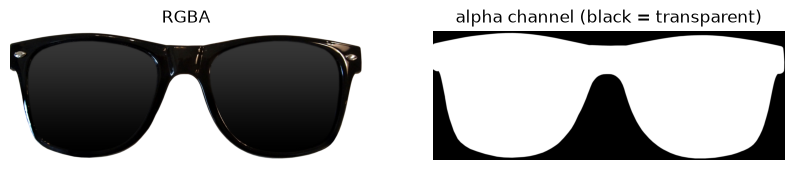

In [2]:
sunglasses = cv2.imread(str(config.IMAGES_DIR / "sunglasses.png"), cv2.IMREAD_UNCHANGED)  # BGRA
print("shape:", sunglasses.shape)
fig, axes = plt.subplots(1, 2, figsize=(10, 2.5))
axes[0].imshow(cv2.cvtColor(sunglasses, cv2.COLOR_BGRA2RGBA)); axes[0].set_title("RGBA")
axes[1].imshow(sunglasses[:, :, 3], cmap="gray"); axes[1].set_title("alpha channel (black = transparent)")
for ax in axes:
    ax.axis("off")
plt.show()

## Placement from the keypoints

Using the 0-based indices from `assets/landmark_index.png`:

| | Keypoints |
|---|---|
| top-left corner | 17, the outer end of the left eyebrow |
| width | 17 → 26, from one outer eyebrow corner to the other |
| height | 27 → 34, the length of the nose bridge |

![landmark index](../assets/landmark_index.png)

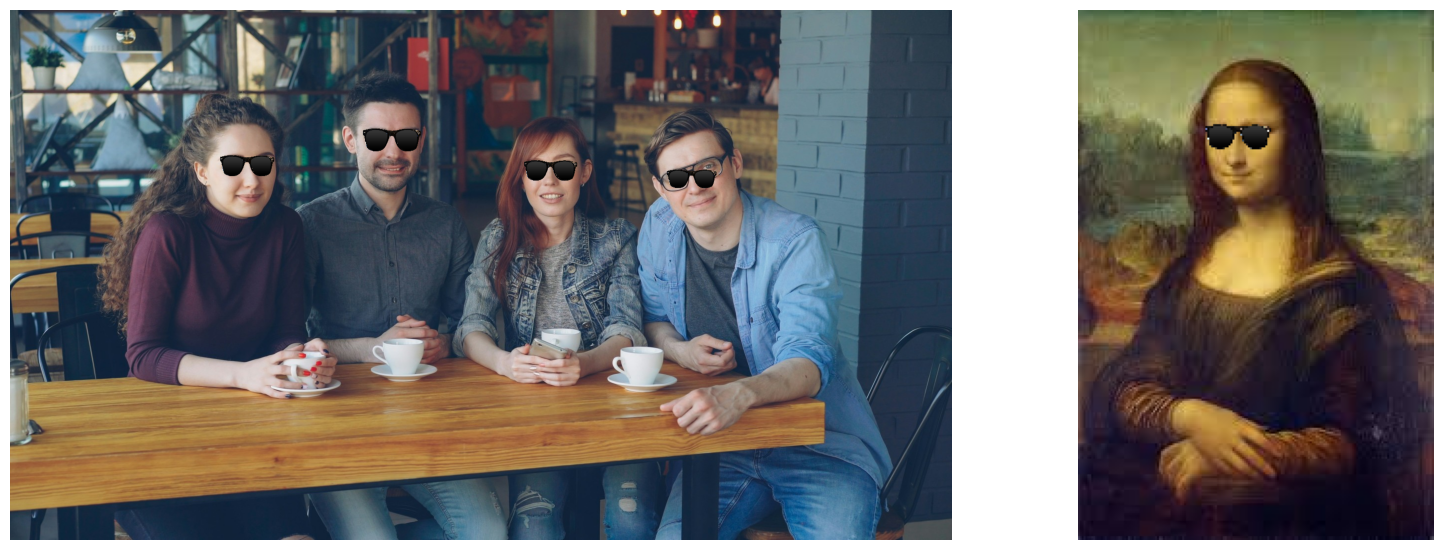

In [3]:
def add_sunglasses(path, min_size=0.12):  # min_size chosen in notebook 04
    image = load_rgb(path)
    boxes = detect_faces(image, min_size=min_size)
    keypoints = predict_keypoints(net, image, boxes)
    out = image
    for pts in keypoints:
        out = overlay_sunglasses(out, pts, sunglasses)
    return image, keypoints, out


fig, axes = plt.subplots(1, 2, figsize=(16, 5.6), gridspec_kw={"width_ratios": [1.78, 0.67]})
for ax, name in zip(axes, ["group_cafe.jpg", "mona_lisa.jpg"]):
    _, _, out = add_sunglasses(config.IMAGES_DIR / name)
    ax.imshow(out); ax.axis("off")
fig.tight_layout()
plt.show()

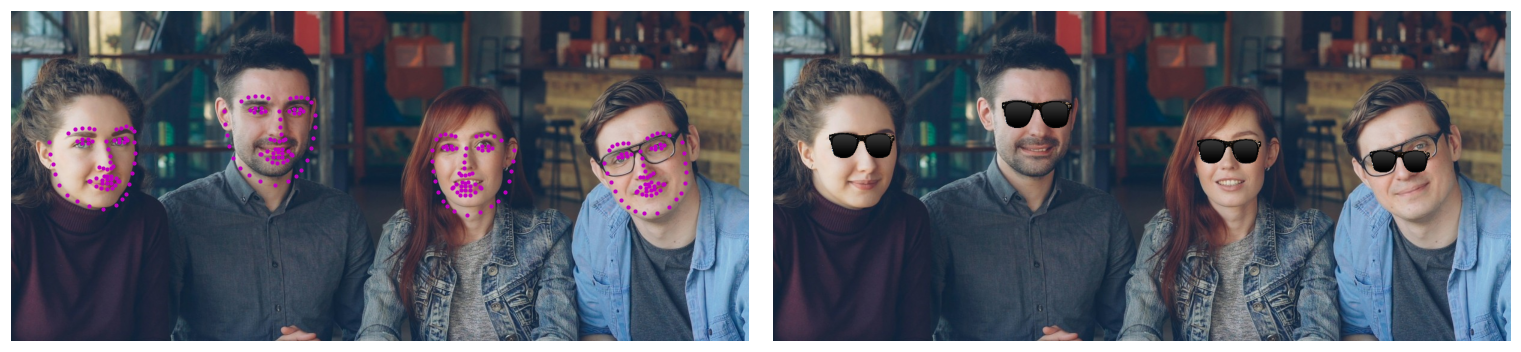

In [4]:
# Figure for the top of the README: predicted keypoints and the filter on the same group photo
# Photo: Vitaly Gariev on Unsplash (https://unsplash.com/photos/four-friends-are-sitting-together-at-a-table-wAntJVFnMh8)
image, keypoints, out = add_sunglasses(config.IMAGES_DIR / "group_cafe.jpg")
top, bottom, left, right = 90, 640, 330, 1560   # crop to the faces
fig, axes = plt.subplots(1, 2, figsize=(14, 3.3), dpi=110)
axes[0].imshow(image[top:bottom, left:right])
for pts in keypoints:
    axes[0].scatter(pts[:, 0] - left, pts[:, 1] - top, s=3, c="m")
axes[1].imshow(out[top:bottom, left:right])
for ax in axes:
    ax.axis("off")
fig.tight_layout()
fig.savefig(config.ASSETS_DIR / "hero.png", bbox_inches="tight", pad_inches=0.05)
plt.show()

**Result.** The glasses sit on the eyes of all four people in the group photo and on the Mona Lisa, using only predicted keypoints. The two frontal faces in the middle get the best fit. On the man on the right, who tilts his head and wears glasses, the overlay sits on his own frames but is slightly shifted toward the right of his face, because it is axis-aligned and placed from eyebrow keypoints that follow the tilt only partially.

**Next step: rotation.** The overlay is axis-aligned, so a head that tilts sideways (roll) gets horizontal glasses. Rotating the PNG by the angle of the eye line (points 36 → 45) and scaling it by the inter-ocular distance would make the overlay follow head roll. It is not implemented here.